<a href="https://colab.research.google.com/github/Divya4325/Cleaned-Banana-Classification-Detection/blob/main/05_Model_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
! unzip "/content/drive/MyDrive/Clean_Banana_dataset.zip" -d /content/Clean_Banana_dataset

Streaming output truncated to the last 5000 lines.
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-freshripe-79154a8c-1d0a-11ec-896b-d8c4975e38aa_jpg.rf.ec91229bfa92be00bc14932ffa62d25b.jpg  
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-banana-e48317e6-394a-11ec-beae-d8c4975e38aa_jpg.rf.9679379f6da16d159501aa1e1f270770.jpg  
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-banana-ee3ca35f-394a-11ec-80ab-d8c4975e38aa_jpg.rf.df991bd3bffedada558b36e83cfb940a.jpg  
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-ripe-951db010-1d0a-11ec-b77d-d8c4975e38aa_jpg.rf.99cdda282f3c928fcf14fd191f9ba5c1.jpg  
  inflating: /content/Clean_Banana_dataset/content/Clean_Banana_dataset/train/ripe/musa-acuminata-freshripe-787147b6-1d0a-11ec-ae8f-d8c4975e38aa_jpg.rf.74ffca68f00adc435cbff61c4a9f19af.jpg  
  inf

**Create the test data generator**

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
test_datagen = ImageDataGenerator(rescale=1./255)
test_generator = test_datagen.flow_from_directory(
    "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/test",
    target_size = (416,416),
    batch_size =32,
    class_mode = "categorical",
    shuffle = False
)

Found 562 images belonging to 4 classes.


In [ ]:
from tensorflow.keras.models import load_model
model = load_model("/content/drive/MyDrive/cnn_model.h5")

**Evaluate the Model**

In [ ]:
test_loss, test_accuracy = model.evaluate(test_generator)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 248ms/step - accuracy: 0.8327 - loss: 0.4131
Test Loss: 0.413083016872406
Test Accuracy: 0.8327401876449585


**Predict test Images**

In [ ]:
import numpy as np
pred = model.predict(test_generator)
pred_classes = np.argmax(pred,axis=1)
true_classes = test_generator.classes

18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 174ms/step


**Classification Report**

In [ ]:
from sklearn.metrics import classification_report
report = classification_report(
    true_classes,
    pred_classes,
    target_names = test_generator.class_indices.keys(),
    output_dict = True
)
print(classification_report(
    true_classes,
    pred_classes,
target_names = test_generator.class_indices.keys()
))
CNN_accuracy = report["accuracy"]
CNN_precision = report["weighted avg"]["precision"]
CNN_recall = report["weighted avg"]["recall"]
CNN_f1 = report["weighted avg"]["f1-score"]

print("CNN Accuracy :", CNN_accuracy)
print("CNN Precision:", CNN_precision)
print("CNN Recall   :", CNN_recall)
print("CNN F1-score :", CNN_f1)

              precision    recall  f1-score   support

    overripe       0.76      0.79      0.77       113
        ripe       0.92      0.79      0.85       154
      rotten       0.75      0.91      0.83       185
      unripe       1.00      0.80      0.89       110

    accuracy                           0.83       562
   macro avg       0.86      0.82      0.83       562
weighted avg       0.85      0.83      0.83       562

CNN Accuracy : 0.8327402135231317
CNN Precision: 0.8483920208347769
CNN Recall   : 0.8327402135231317
CNN F1-score : 0.8345940685652777


**Confusion Matrix**

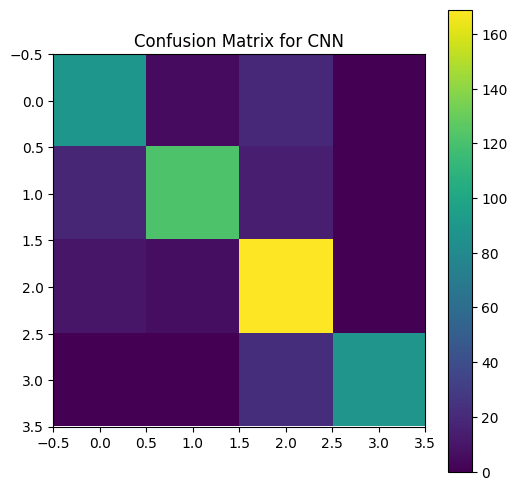

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
cm = confusion_matrix(true_classes,pred_classes)
plt.figure(figsize=(6,6))
plt.imshow(cm)
plt.title("Confusion Matrix for CNN")
plt.colorbar()
plt.show()

**Training Graphs**

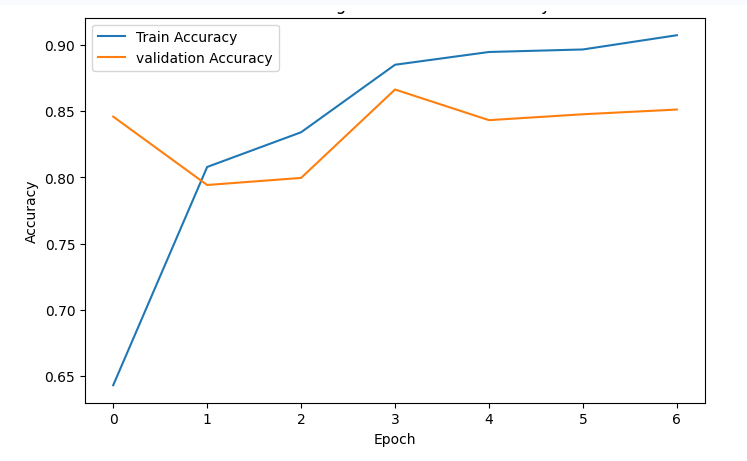

In [ ]:
from IPython.display import Image,display
display(Image(filename="/content/Accuracy_graph.png"))

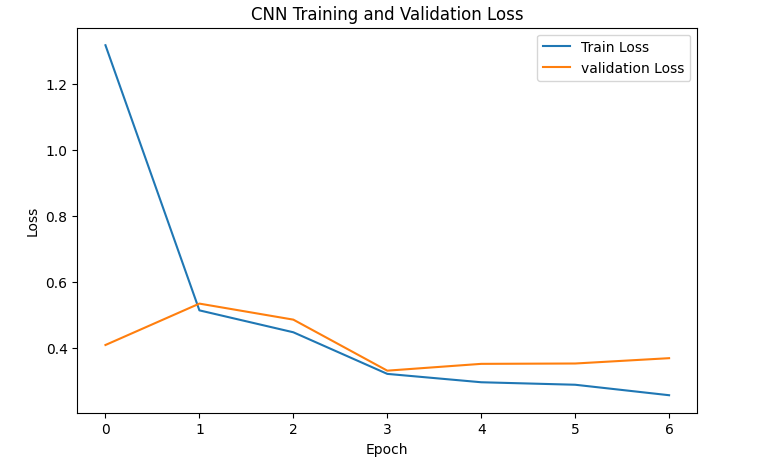

In [ ]:
display(Image(filename="/content/Loss Graph.png"))

**Measure Inference Time**

In [ ]:
import time

start = time.time()

model.predict(test_generator)

end = time.time()

CNN_time = end - start

print("CNN Inference Time:", CNN_time, "seconds")

18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 154ms/step
CNN Inference Time: 3.0485520362854004 seconds


# **MobileNetV2**

In [ ]:
from tensorflow.keras.models import load_model
model = load_model("/content/drive/MyDrive/mobilenetv2_banana_model.h5")

In [ ]:
model.compile(
    optimizer ='adam',
    loss ='categorical_crossentropy',
    metrics = ['accuracy']
)

**Test Generator for MobileNetV2**

In [ ]:
test_path  = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/test"

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
test_datagen_mobilenet = ImageDataGenerator(preprocessing_function=mobilenet_preprocess)
test_gen_mobilenet = test_datagen_mobilenet.flow_from_directory(
    test_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 562 images belonging to 4 classes.


**Evaluate the Model**

In [ ]:
test_loss, test_accuracy = model.evaluate(test_gen_mobilenet)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

18/18 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.8932 - loss: 0.3124
Test Loss: 0.3124021589756012
Test Accuracy: 0.8932384252548218


**Predict test Images**

In [ ]:
import numpy as np
pred = model.predict(test_gen_mobilenet)
pred_classes = np.argmax(pred,axis=1)
true_classes = test_gen_mobilenet.classes

18/18 ━━━━━━━━━━━━━━━━━━━━ 31s 972ms/step


**Classification Report**

In [ ]:
from sklearn.metrics import classification_report
report = classification_report(
    true_classes,
    pred_classes,
    target_names = test_gen_mobilenet.class_indices.keys(),
    output_dict = True
)
print(classification_report(
    true_classes,
    pred_classes,
target_names = test_gen_mobilenet.class_indices.keys()
))
MOBILENET_accuracy = report["accuracy"]
MOBILENET_precision = report["weighted avg"]["precision"]
MOBILENET_recall = report["weighted avg"]["recall"]
MOBILENET_f1 = report["weighted avg"]["f1-score"]

print("MOBILENET Accuracy :", MOBILENET_accuracy)
print("MOBILENET Precision:", MOBILENET_precision)
print("MOBILENET Recall   :", MOBILENET_recall)
print("MOBILENET F1-score :", MOBILENET_f1)

              precision    recall  f1-score   support

    overripe       0.88      0.93      0.90       113
        ripe       0.94      0.85      0.89       154
      rotten       0.84      0.94      0.89       185
      unripe       0.95      0.85      0.89       110

    accuracy                           0.89       562
   macro avg       0.90      0.89      0.89       562
weighted avg       0.90      0.89      0.89       562

MOBILENET Accuracy : 0.8932384341637011
MOBILENET Precision: 0.8977249056388524
MOBILENET Recall   : 0.8932384341637011
MOBILENET F1-score : 0.8933195159207469


**Confusion Matrix**

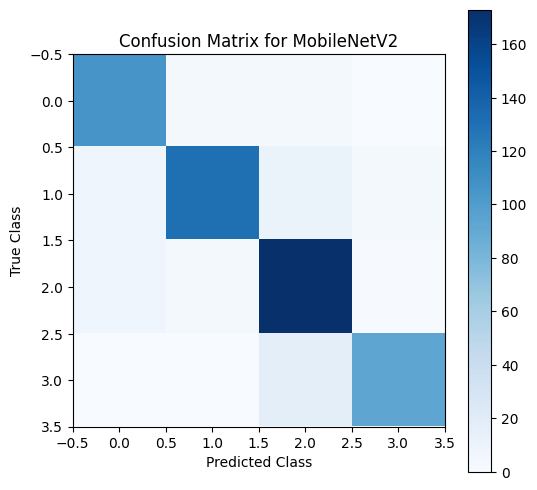

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
cm = confusion_matrix(true_classes,pred_classes)
plt.figure(figsize=(6,6))
plt.imshow(cm,cmap='Blues')
plt.title("Confusion Matrix for MobileNetV2")
plt.colorbar()
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()

**Training Graphs**

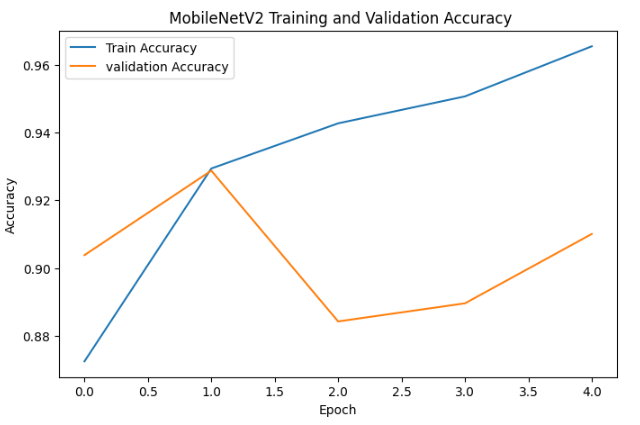

In [ ]:
from IPython.display import Image,display
display(Image(filename="/content/Mobilenet_Accuracy.png"))

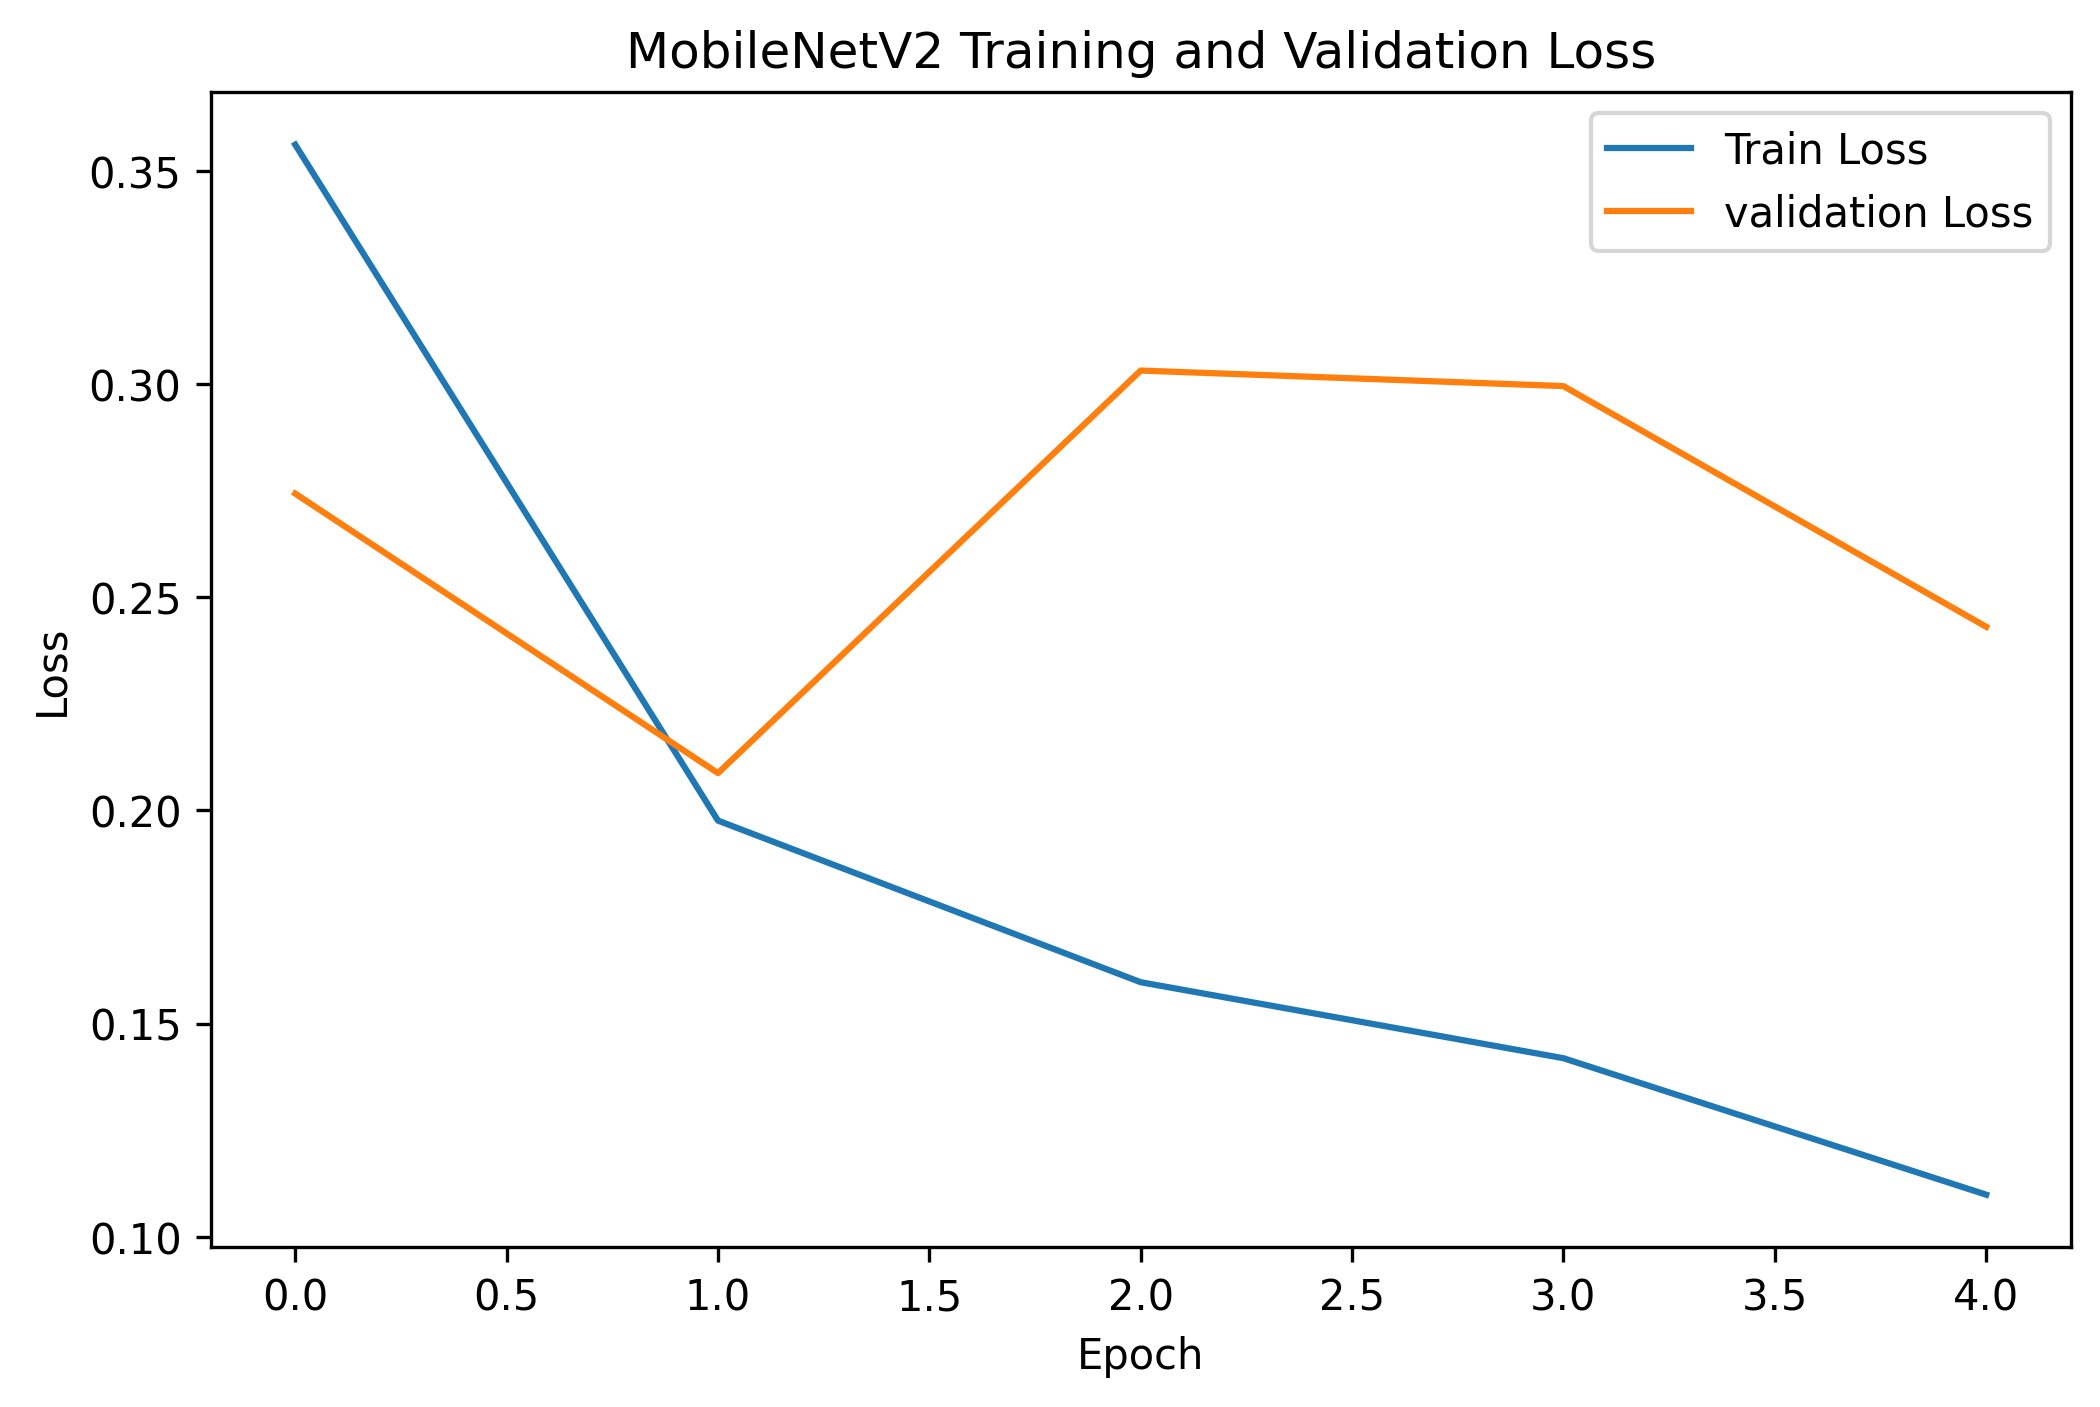

In [ ]:
display(Image(filename="/content/mobilenetv2_loss_graph.png"))

**Measure Inference Time**

In [ ]:
import time

start = time.time()

model.predict(test_generator)

end = time.time()

MOBILENET_time = end - start

print("MOBILENET Inference Time:", MOBILENET_time, "seconds")

18/18 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step
MOBILENET Inference Time: 74.13699865341187 seconds


# **EfficientNetB0**

In [ ]:
from tensorflow.keras.models import load_model
model = load_model("/content/drive/MyDrive/efficientnetb0_banana_model.h5")

**Test Generator for EfficientNetB0**

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input as efficienet_preprocess
test_datagen_efficientnet = ImageDataGenerator(preprocessing_function=efficienet_preprocess)
test_gen_efficientnet = test_datagen_efficientnet.flow_from_directory(
    test_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 562 images belonging to 4 classes.


**Evaluate the Model**

In [ ]:
test_loss, test_accuracy = model.evaluate(test_gen_efficientnet)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

18/18 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.9609 - loss: 0.1419
Test Loss: 0.14186470210552216
Test Accuracy: 0.9608541131019592


**Predict test Images**

In [ ]:
import numpy as np
pred = model.predict(test_gen_efficientnet)
pred_classes = np.argmax(pred,axis=1)
true_classes = test_gen_efficientnet.classes

18/18 ━━━━━━━━━━━━━━━━━━━━ 62s 2s/step


**Classification Report**

In [ ]:
from sklearn.metrics import classification_report
report = classification_report(
    true_classes,
    pred_classes,
    target_names = test_gen_efficientnet.class_indices.keys(),
    output_dict = True
)
print(classification_report(
    true_classes,
    pred_classes,
target_names = test_gen_efficientnet.class_indices.keys()
))
EFFICIENTNET_accuracy = report["accuracy"]
EFFICIENTNET_precision = report["weighted avg"]["precision"]
EFFICIENTNET_recall = report["weighted avg"]["recall"]
EFFICIENTNET_f1 = report["weighted avg"]["f1-score"]

print("EFFICIENTNET Accuracy :", EFFICIENTNET_accuracy)
print("EFFICIENTNET Precision:", EFFICIENTNET_precision)
print("EFFICIENTNET Recall   :", EFFICIENTNET_recall)
print("EFFICIENTNET F1-score :", EFFICIENTNET_f1 )

              precision    recall  f1-score   support

    overripe       0.93      0.98      0.95       113
        ripe       0.99      0.92      0.95       154
      rotten       0.96      0.97      0.96       185
      unripe       0.96      0.99      0.98       110

    accuracy                           0.96       562
   macro avg       0.96      0.96      0.96       562
weighted avg       0.96      0.96      0.96       562

EFFICIENTNET Accuracy : 0.9608540925266904
EFFICIENTNET Precision: 0.96197909100594
EFFICIENTNET Recall   : 0.9608540925266904
EFFICIENTNET F1-score : 0.9607699625681779


**Confusion Matrix**

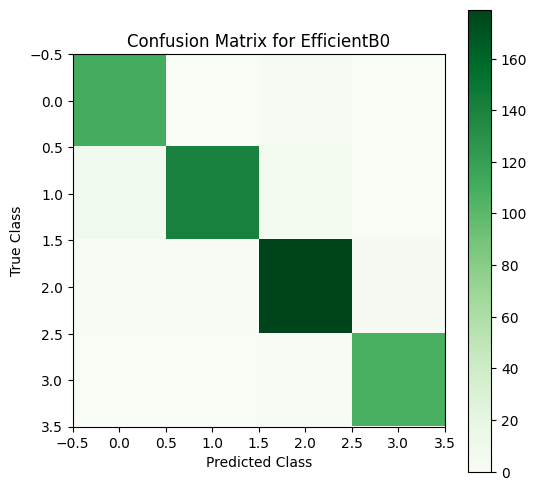

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
cm = confusion_matrix(true_classes,pred_classes)
plt.figure(figsize=(6,6))
plt.imshow(cm,cmap='Greens')
plt.title("Confusion Matrix for EfficientB0")
plt.colorbar()
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()

**Measure Inference Time**

In [ ]:
import time

start = time.time()

model.predict(test_generator)

end = time.time()

EFFICIENTNET_time = end - start

print("EFFICIENTNET Inference Time:", EFFICIENTNET_time, "seconds")

18/18 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step
EFFICIENTNET Inference Time: 80.82809114456177 seconds


**Training Graphs**

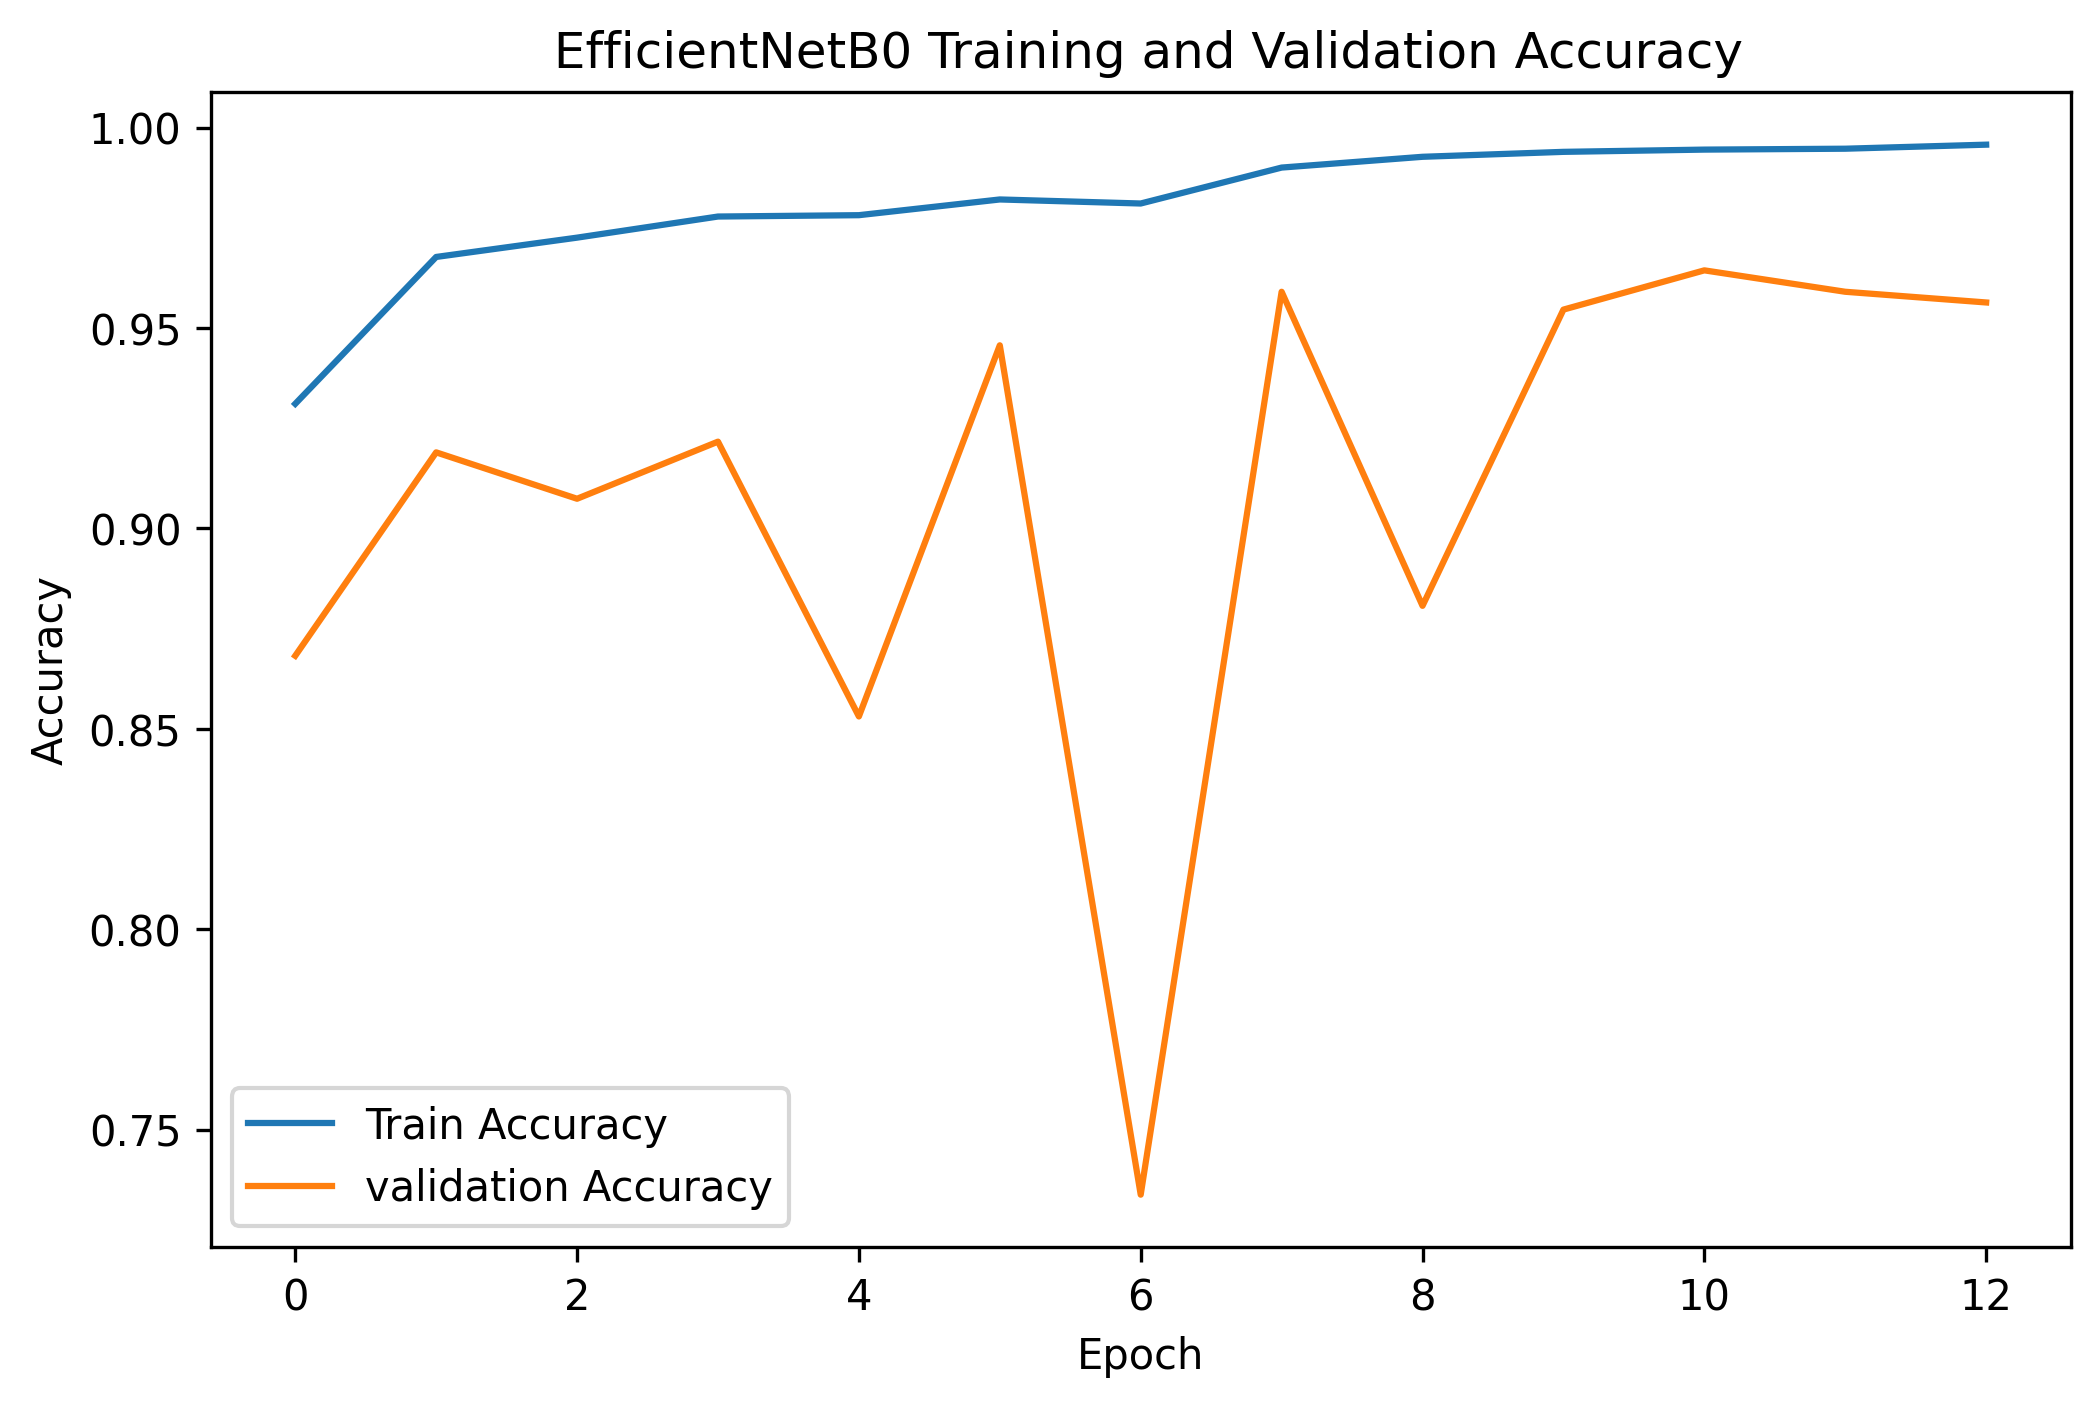

In [ ]:
from IPython.display import Image,display
display(Image(filename="/content/efficientnetb0_accuracy_graph.png"))

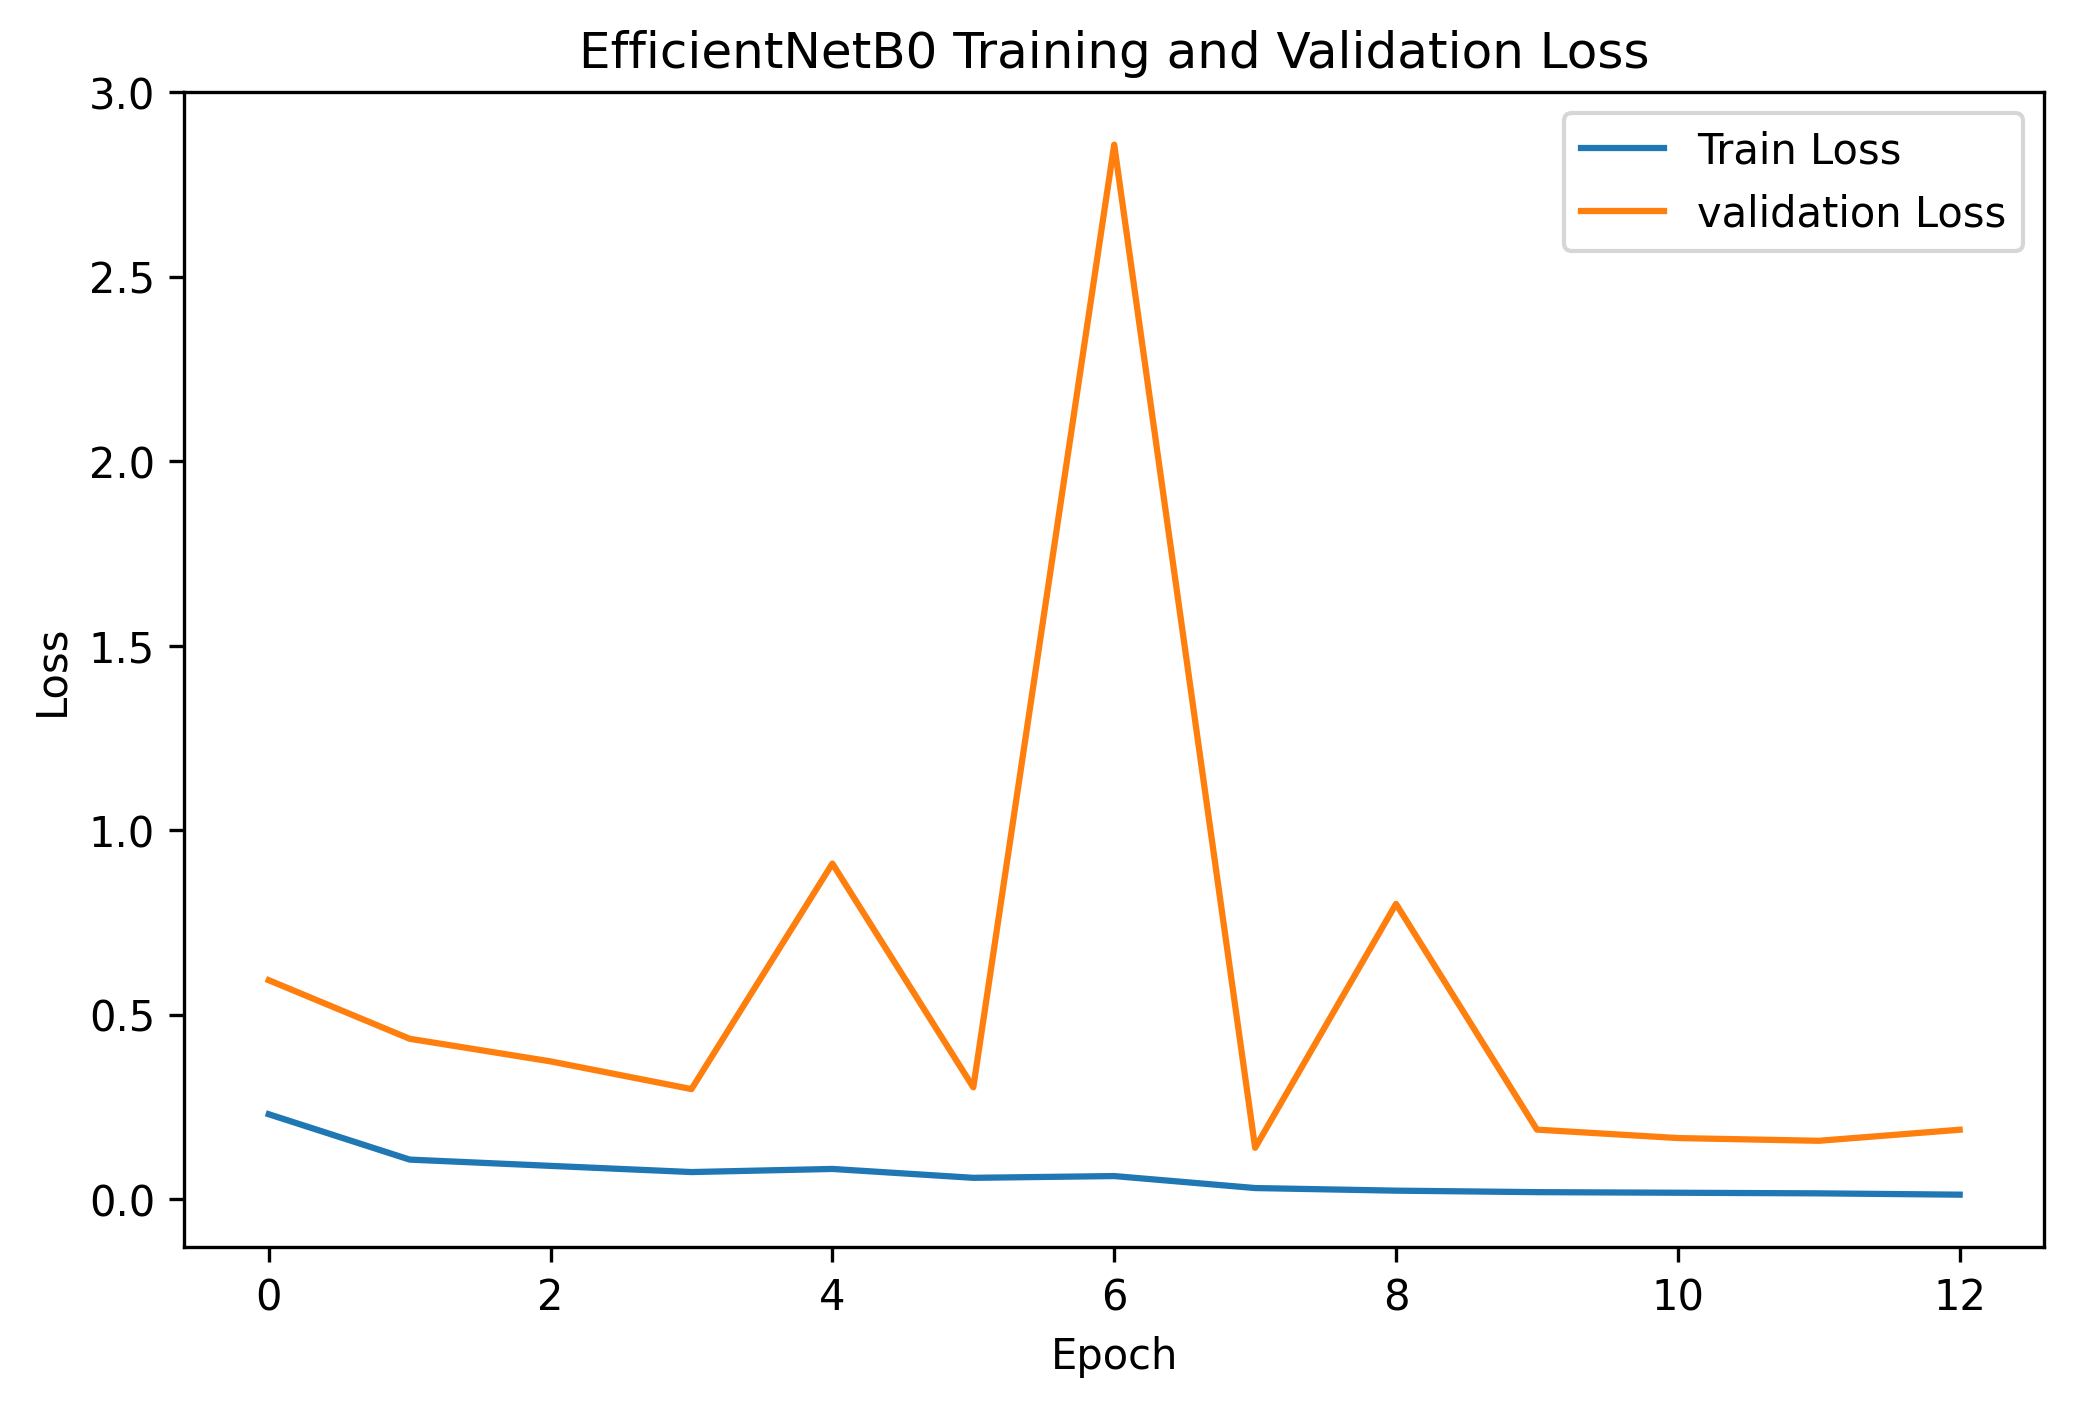

In [ ]:
display(Image(filename="/content/efficientnetb0_loss_graph.png"))

# **ResNet50**

In [ ]:
from tensorflow.keras.models import load_model
model = load_model("/content/drive/MyDrive/resnet50_banana_model.h5")

**Test Generator for ResNet50**

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import preprocess_input as resnet_preprocess
test_datagen_renest = ImageDataGenerator(preprocessing_function=resnet_preprocess)
test_gen_resnet = test_datagen_renest.flow_from_directory(
    test_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 562 images belonging to 4 classes.


**Evaluate the Model**

In [ ]:
test_loss, test_accuracy = model.evaluate(test_gen_resnet)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

18/18 ━━━━━━━━━━━━━━━━━━━━ 14s 362ms/step - accuracy: 0.8843 - loss: 0.5466
Test Loss: 0.5465630888938904
Test Accuracy: 0.8843416571617126


**Predict test Images**

In [ ]:
import numpy as np
pred = model.predict(test_gen_resnet)
pred_classes = np.argmax(pred,axis=1)
true_classes = test_gen_resnet.classes

18/18 ━━━━━━━━━━━━━━━━━━━━ 13s 421ms/step


**Classification Report**

In [ ]:
from sklearn.metrics import classification_report
report = classification_report(
    true_classes,
    pred_classes,
    target_names = test_gen_resnet.class_indices.keys(),
    output_dict = True
)
print(classification_report(
    true_classes,
    pred_classes,
target_names = test_gen_resnet.class_indices.keys()
))
RESNET_accuracy = report["accuracy"]
RESNET_precision = report["weighted avg"]["precision"]
RESNET_recall = report["weighted avg"]["recall"]
RESNET_f1 = report["weighted avg"]["f1-score"]

print("RESNET Accuracy :", RESNET_accuracy )
print("RESNET Precision:", RESNET_precision)
print("RESNET Recall   :", RESNET_recall)
print("RESNET F1-score :", RESNET_f1)

              precision    recall  f1-score   support

    overripe       0.82      0.94      0.88       113
        ripe       0.99      0.67      0.80       154
      rotten       0.83      0.97      0.90       185
      unripe       0.96      0.98      0.97       110

    accuracy                           0.88       562
   macro avg       0.90      0.89      0.89       562
weighted avg       0.90      0.88      0.88       562

RESNET Accuracy : 0.8843416370106761
RESNET Precision: 0.8979917330552027
RESNET Recall   : 0.8843416370106761
RESNET F1-score : 0.8800442154430365


**Confusion Matrix**

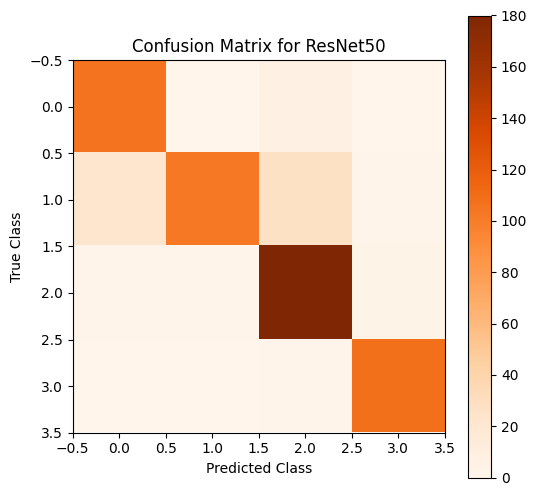

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
cm = confusion_matrix(true_classes,pred_classes)
plt.figure(figsize=(6,6))
plt.imshow(cm,cmap='Oranges')
plt.title("Confusion Matrix for ResNet50")
plt.colorbar()
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()

**Measure Inference Time**

In [ ]:
import time

start = time.time()

model.predict(test_generator)

end = time.time()

RESNET_time = end - start

print("RESNETNET Inference Time:", RESNET_time, "seconds")

18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 253ms/step
RESNETNET Inference Time: 5.360105991363525 seconds


**Training Graphs**

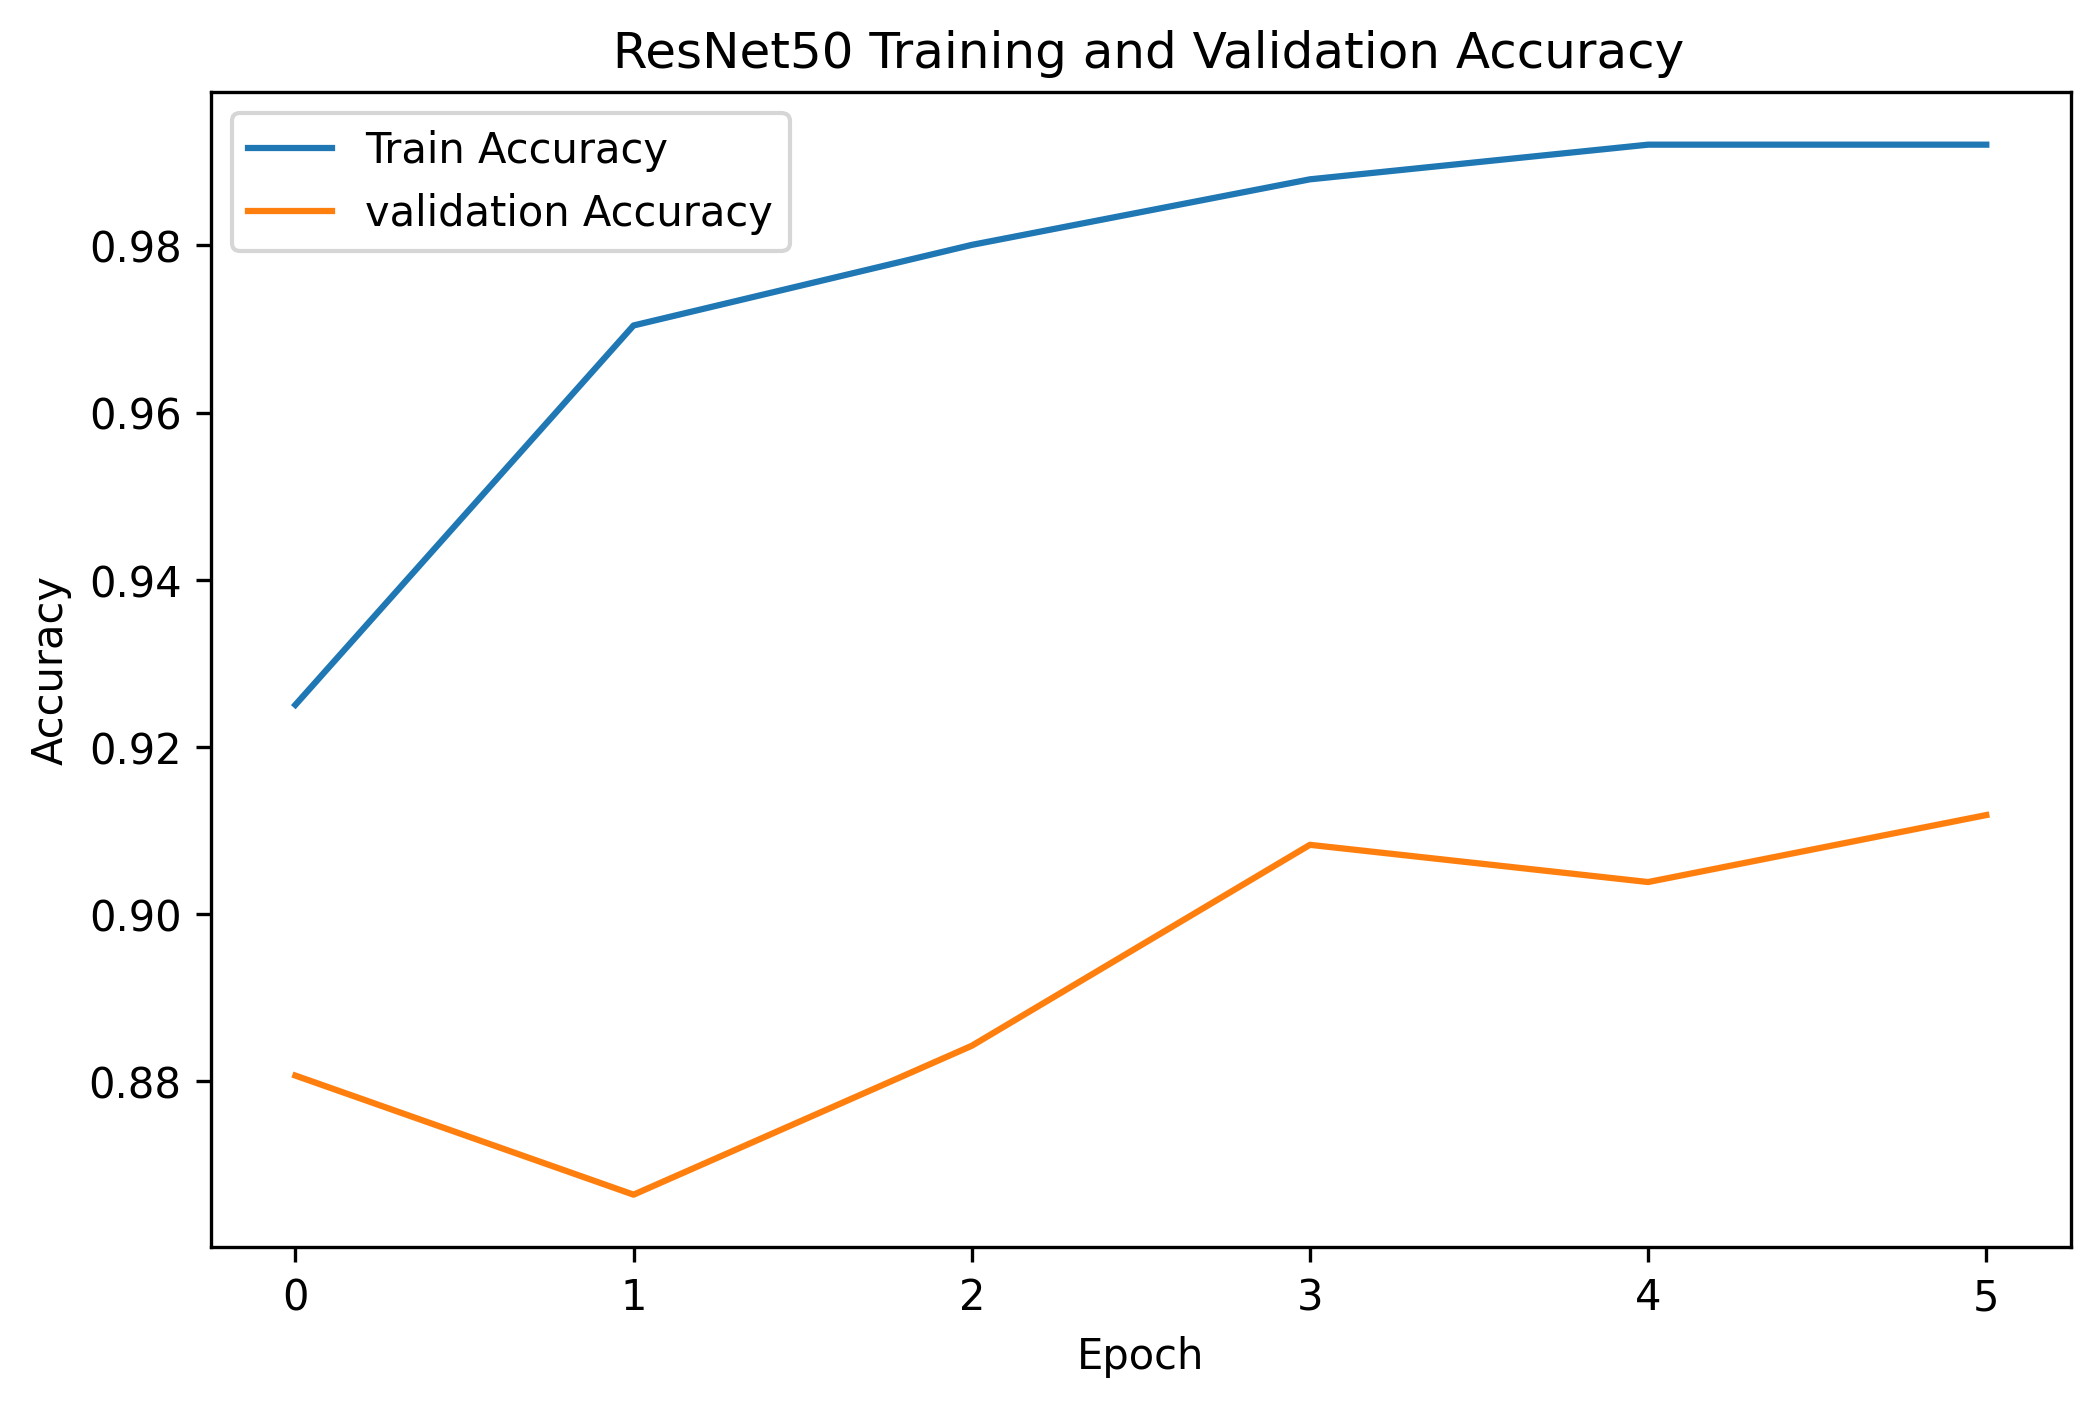

In [ ]:
from IPython.display import Image,display
display(Image(filename="/content/resnet50_accuracy_graph.png"))

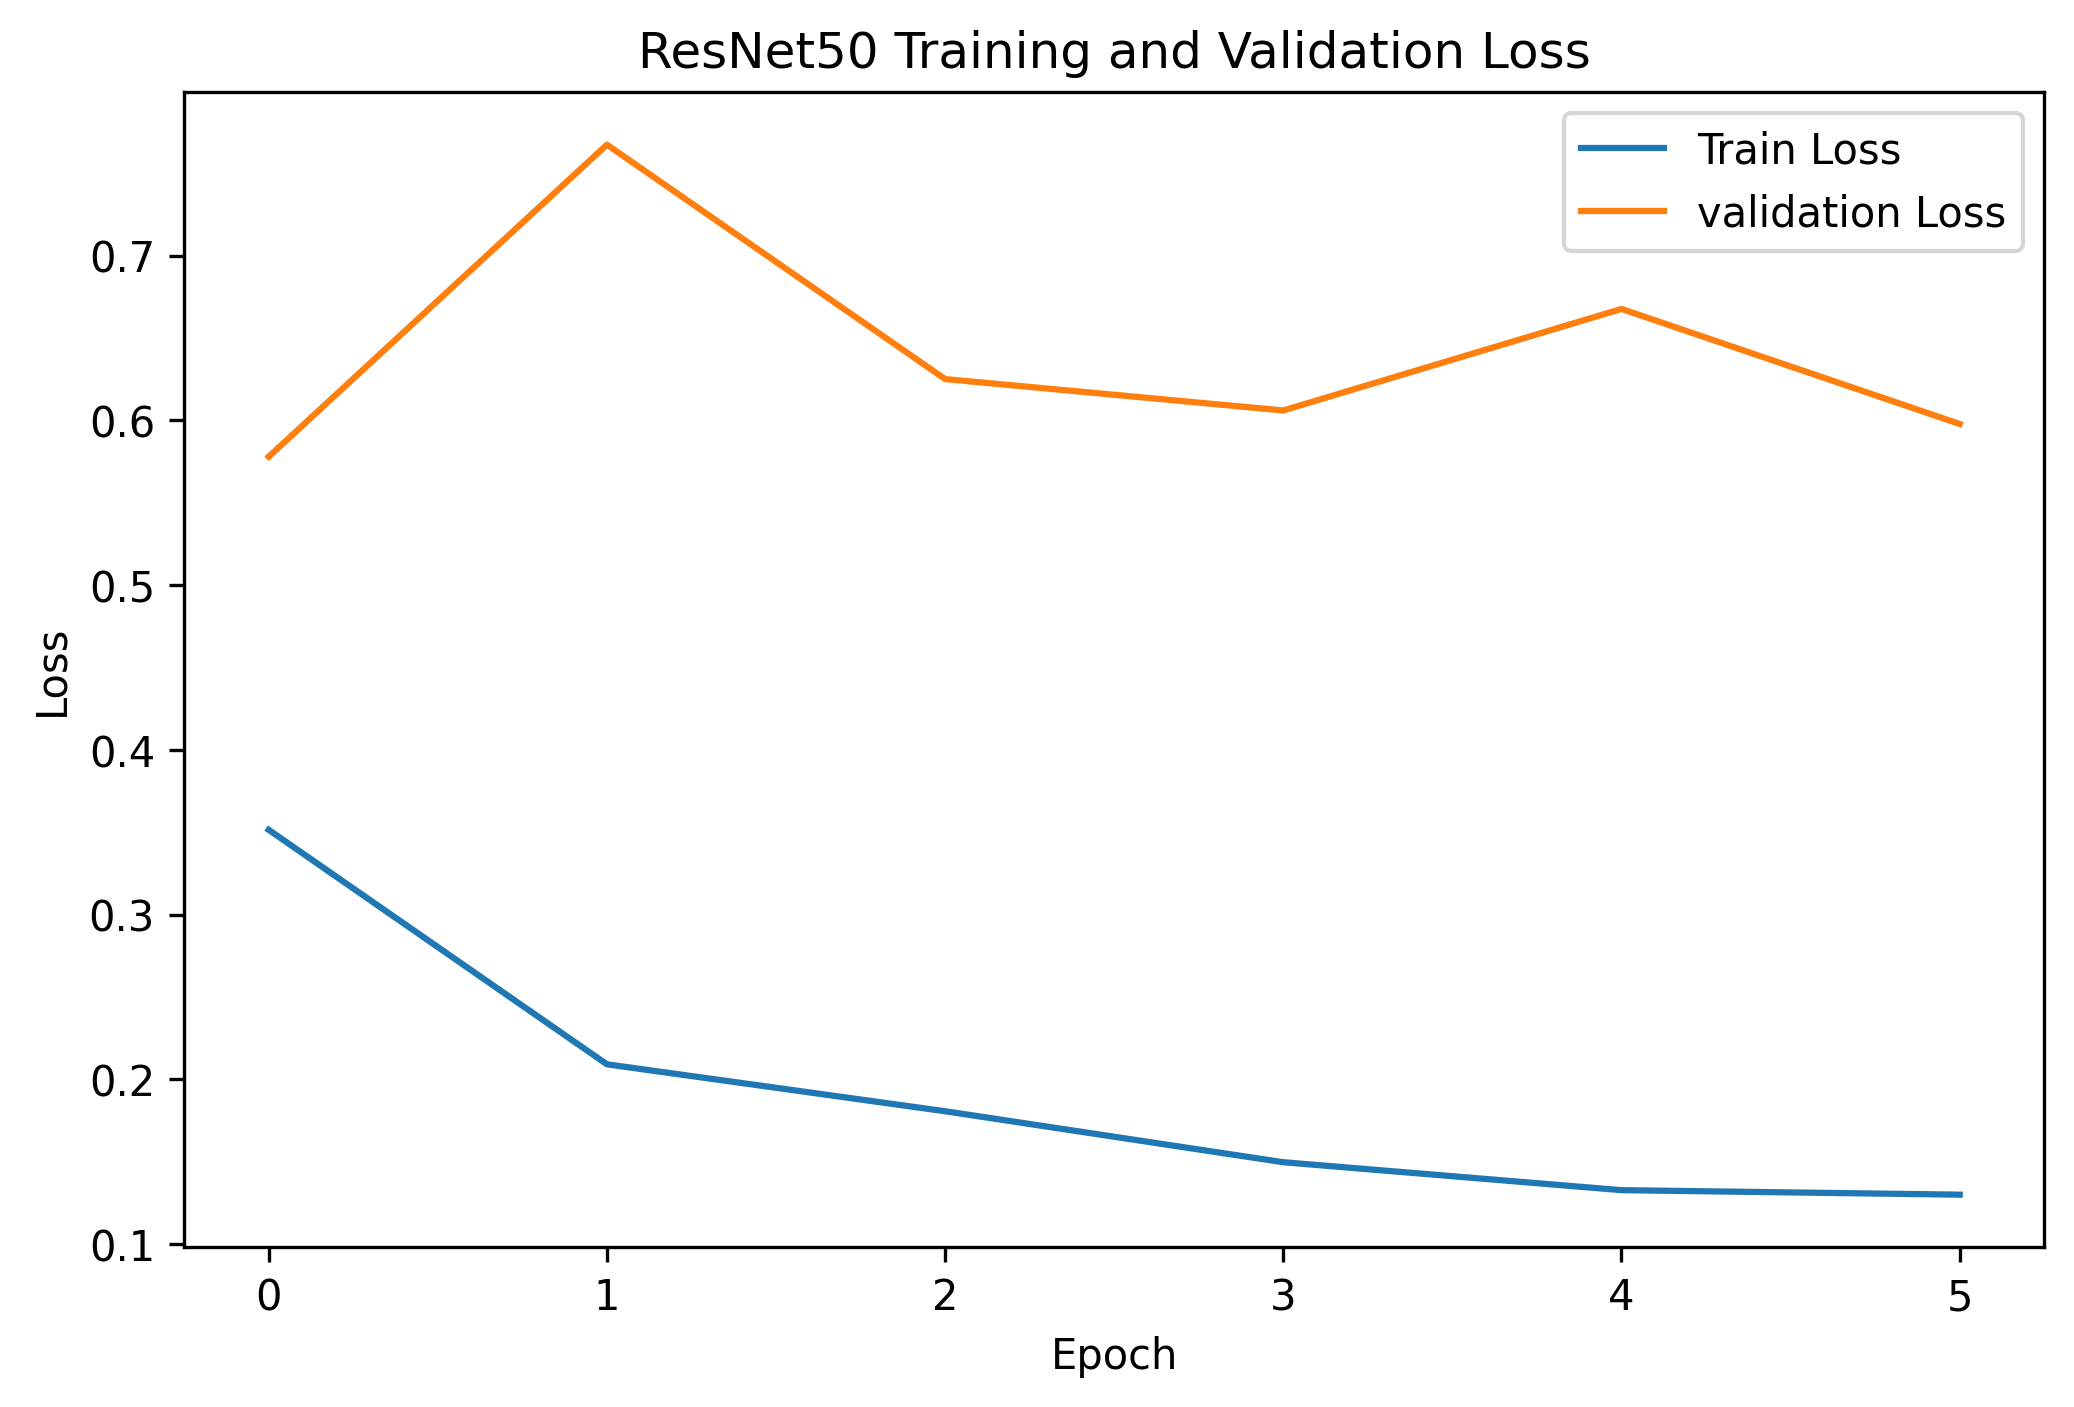

In [ ]:
display(Image(filename="/content/resnet50_loss_graph.png"))

# **Yolo Classification Test Evaluation**

In [ ]:
pip install ultralytics

In [ ]:
from ultralytics import YOLO

In [ ]:
model = YOLO("/content/drive/MyDrive/best.pt")

**Evaluation on Test data**

In [ ]:
import os
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_true = []
y_pred = []

test_path = "/content/Clean_Banana_dataset/content/Clean_Banana_dataset/test"

class_names = ["overripe", "ripe", "rotten", "unripe"]

for class_index, class_name in enumerate(class_names):

    class_folder = os.path.join(test_path, class_name)

    for image_name in os.listdir(class_folder):

        image_path = os.path.join(class_folder, image_name)

        # Predict one image
        result = model.predict(
            source=image_path,
            imgsz=224,
            verbose=False
        )[0]

        predicted_class = result.probs.top1

        y_true.append(class_index)
        y_pred.append(predicted_class)

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, average="weighted"))
print("Recall   :", recall_score(y_true, y_pred, average="weighted"))
print("F1-score :", f1_score(y_true, y_pred, average="weighted"))

Accuracy : 0.9786476868327402
Precision: 0.9787978855503853
Recall   : 0.9786476868327402
F1-score : 0.9786706181271493


**Classification Report**

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=["overripe", "ripe", "unripe", "rotten"],
    output_dict=True
)

YOLO_cls_accuracy = report["accuracy"]
YOLO_cls_precision = report["weighted avg"]["precision"]
YOLO_cls_recall = report["weighted avg"]["recall"]
YOLO_cls_f1 = report["weighted avg"]["f1-score"]

print("YOLO Classification Accuracy :", YOLO_cls_accuracy)
print("YOLO Classification Precision:", YOLO_cls_precision)
print("YOLO Classification Recall   :", YOLO_cls_recall)
print("YOLO Classification F1-score :", YOLO_cls_f1)

YOLO Classification Accuracy : 0.9786476868327402
YOLO Classification Precision: 0.9787978855503853
YOLO Classification Recall   : 0.9786476868327402
YOLO Classification F1-score : 0.9786706181271493


**Confusion Matrix**

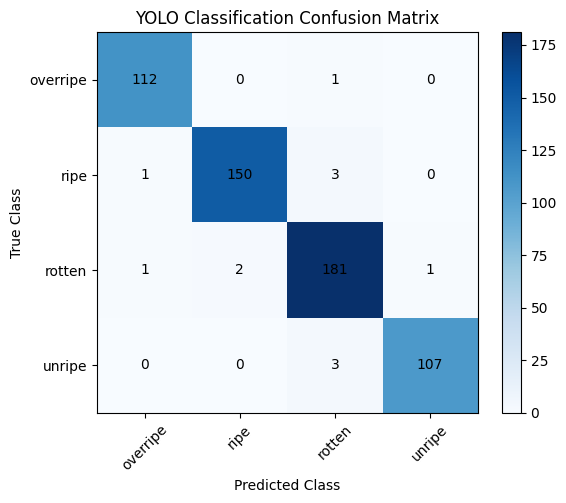

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(len(class_names)), class_names, rotation=45)
plt.yticks(range(len(class_names)), class_names)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("YOLO Classification Confusion Matrix")

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

**Measure Inference Time**

In [ ]:
import time

start_time = time.time()

for class_index, class_name in enumerate(class_names):

    class_folder = os.path.join(test_path, class_name)

    for image_name in os.listdir(class_folder):

        image_path = os.path.join(class_folder, image_name)

        result = model.predict(
            source=image_path,
            imgsz=224,
            verbose=False
        )[0]

        predicted_class = result.probs.top1

        y_true.append(class_index)
        y_pred.append(predicted_class)

end_time = time.time()

YOLO_cls_time = end_time - start_time

print("YOLO Classification Inference Time:",
      YOLO_cls_time, "seconds")

YOLO Classification Inference Time: 5.880635976791382 seconds


# **Comparison Report for All Models**

In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "CNN",
        "MobileNetV2",
        "ResNet50",
        "EfficientNetB0",
        "YOLO Classification"
    ],

    "Accuracy": [
        CNN_accuracy,
        MOBILENET_accuracy,
        RESNET_accuracy,
        EFFICIENTNET_accuracy,
        YOLO_cls_accuracy,
    ],

    "Precision": [
        CNN_precision,
        MOBILENET_precision,
        RESNET_precision,
        EFFICIENTNET_precision,
        YOLO_cls_precision,
    ],

    "Recall": [
        CNN_recall,
        MOBILENET_recall,
        RESNET_recall,
        EFFICIENTNET_recall,
        YOLO_cls_recall,
    ],

    "F1-score": [
        CNN_f1,
        MOBILENET_f1,
        RESNET_f1,
        EFFICIENTNET_f1,
        YOLO_cls_f1,
    ],

    "Inference Time (ms)": [
        CNN_time,
        MOBILENET_time,
        RESNET_time,
        EFFICIENTNET_time,
        YOLO_cls_time,
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1-score,Inference Time (ms)
0,CNN,0.832740,0.848392,0.832740,0.834594,3.048552
1,MobileNetV2,0.893238,0.897725,0.893238,0.893320,74.136999
2,ResNet50,0.884342,0.897992,0.884342,0.880044,5.360106
3,EfficientNetB0,0.960854,0.961979,0.960854,0.960770,80.828091
4,YOLO Classification,0.978648,0.978798,0.978648,0.978671,5.880636


# **YOLO Object Detection Evaluation**

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.1/46.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.9 MB/s eta 0:00:00


In [ ]:
!unzip "/content/drive/MyDrive/Yolo Project.v1i.yolov8.zip"

Archive:  /content/drive/MyDrive/Yolo Project.v1i.yolov8.zip
 extracting: train/images/musa-acuminata-banana-b3b229f9-394a-11ec-bd6e-d8c4975e38aa_jpg.rf.22a811385045eecf6ca48fe0b6fcc756.jpg  
 extracting: train/images/musa-acuminata-freshunripe-2edfeb7e-2653-11ec-b6fb-d8c4975e38aa_jpg.rf.668337742d462ac4c3783488b61388fa.jpg  
 extracting: train/images/musa-acuminata-banana-9aabbca9-394a-11ec-8bda-d8c4975e38aa_jpg.rf.f91b6563293424e6b48b8e23b28a297c.jpg  
 extracting: train/images/musa-acuminata-freshunripe-2c3640ac-2653-11ec-9d59-d8c4975e38aa_jpg.rf.289f58c28596f204a37273a08ad13b4b.jpg  
 extracting: train/images/musa-acuminata-banana-c4b432aa-394a-11ec-901f-d8c4975e38aa_jpg.rf.0067ea117ab7408ccf52ab86a0324bd8.jpg  
 extracting: train/images/musa-acuminata-mold-e3dc13ee-1d0a-11ec-91aa-d8c4975e38aa_jpg.rf.4e1fa44101d57f39910fd3551752d5e1.jpg  
 extracting: train/images/musa-acuminata-mold-e1d47dce-1d0a-11ec-a1ed-d8c4975e38aa_jpg.rf.80d572c4f93ddf362bc9b5fa13498fe4.jpg  
 extracting: tra

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/Yolo_detection_best.pt")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


# **Evaluation on Test dataset**

In [ ]:
results = model.val(
    data= "/content/data.yaml",
    split="test",
    imgsz= 416
)

Ultralytics 8.4.107 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 813.1±308.1 MB/s, size: 27.7 KB)
val: Scanning /content/test/labels... 88 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 88/88 1.0Kit/s 0.1s
val: New cache created: /content/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.4it/s 2.4s
                   all         88         88      0.999          1      0.995      0.936
Speed: 2.0ms preprocess, 4.4ms inference, 0.0ms loss, 3.1ms postprocess per image
Results saved to /content/runs/detect/val


**Precision, Recall, mAP@50 and mAP@50–95**

In [ ]:
print("Precision:", results.box.mp)
print("Recall:", results.box.mr)
print("mAP@50:", results.box.map50)
print("mAP@50-95:", results.box.map)

Precision: 0.9993045898975065
Recall: 1.0
mAP@50: 0.995
mAP@50-95: 0.9355711878273769


**Evaluation metrics table**

In [ ]:
metrics = {
    "Metric": [
        "Precision",
        "Recall",
        "mAP@50",
        "mAP@50–95"
    ],
    "Score": [
        results.box.mp,
        results.box.mr,
        results.box.map50,
        results.box.map
    ]
}

import pandas as pd

metrics_df = pd.DataFrame(metrics)

# Convert scores to percentages
metrics_df["Score"] = (metrics_df["Score"] * 100).round(2)

metrics_df

,Metric,Score
0,Precision,99.93
1,Recall,100.00
2,mAP@50,99.50
3,mAP@50–95,93.56


# **Inference Time**

In [ ]:
import time
import glob
import numpy as np

test_images = glob.glob(
    "/content/test/images"
)

times = []

for img in test_images[:100]:

    start = time.perf_counter()

    model.predict(
        source=img,
        imgsz=224,
        verbose=False
    )

    end = time.perf_counter()

    times.append(end - start)

avg_time = np.mean(times)

print("Average inference time:", avg_time, "seconds/image")
print("Average inference time:", avg_time * 1000, "ms/image")

Average inference time: 0.725640538999869 seconds/image
Average inference time: 725.640538999869 ms/image


# **Detection visualizations**

In [ ]:
results = model.predict(
    source= "/content/test/images",
    imgsz= 416,
    conf=0.25,
    save=True
)


image 1/88 /content/test/images/musa-acuminata-banana-8b4f22e4-394a-11ec-9d08-d8c4975e38aa_jpg.rf.525ac85c7ba8db70ab8caafd4c6f3969.jpg: 416x416 1 Banana, 15.9ms
image 2/88 /content/test/images/musa-acuminata-banana-8b6bc840-394a-11ec-b09c-d8c4975e38aa_jpg.rf.f19ff8f51c08553750cd1329ef5bb8d3.jpg: 416x416 1 Banana, 13.1ms
image 3/88 /content/test/images/musa-acuminata-banana-8b71ff0b-394a-11ec-ab9a-d8c4975e38aa_jpg.rf.dca71055ee7207e22b40b87c37565923.jpg: 416x416 1 Banana, 12.0ms
image 4/88 /content/test/images/musa-acuminata-banana-8baeeab1-394a-11ec-84c0-d8c4975e38aa_jpg.rf.971f91660d6dab02466c105045b02ce4.jpg: 416x416 1 Banana, 9.2ms
image 5/88 /content/test/images/musa-acuminata-banana-8beffea0-394a-11ec-b5ec-d8c4975e38aa_jpg.rf.2ce444f02b331f9736a6411f368a7e7e.jpg: 416x416 1 Banana, 8.6ms
image 6/88 /content/test/images/musa-acuminata-banana-8bf60ec7-394a-11ec-94b9-d8c4975e38aa_jpg.rf.8d523361ced7fc376a361289f0969e10.jpg: 416x416 1 Banana, 9.9ms
image 7/88 /content/test/images/musa

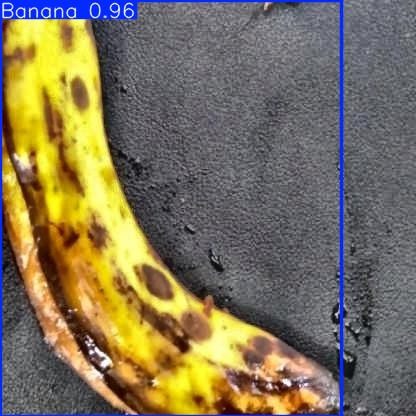

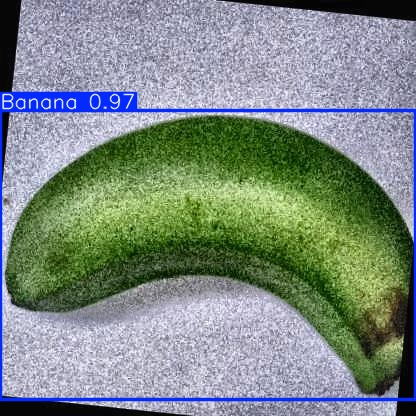

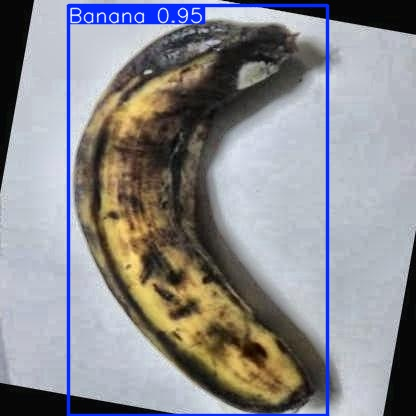

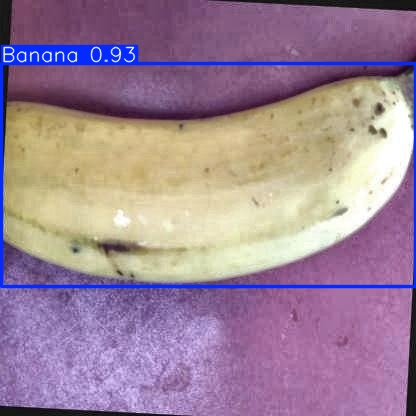

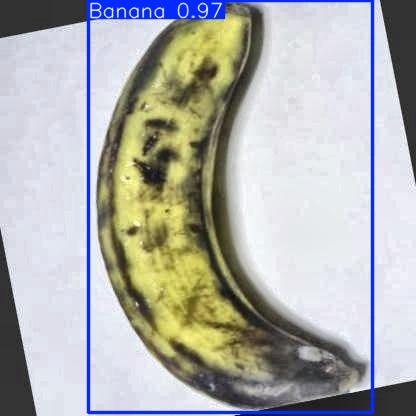

In [ ]:
import glob
from IPython.display import Image, display

images = glob.glob("/content/runs/detect/predict/*.jpg")

for img in images[:5]:
    display(Image(filename=img))

# **Erorr Analysis**

Error Analysis: The YOLO model predictions on the test dataset were visually inspected to identify false positives, false negatives, localization errors, and low-confidence detections. The model showed highly accurate banana localization, with most detected bounding boxes correctly covering the banana objects. Since the test images contain a single banana per image and the model achieved 99.83% precision and 100% recall, very few detection errors were observed during visual inspection.